In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split, validation_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print('Ukuran data:', X.shape)
print('Distribusi kelas:', np.bincount(y))

Ukuran data: (569, 30)
Distribusi kelas: [212 357]


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2, random_state=42, stratify=y)

In [5]:
# Model tanpa pruning (tumbuh penuh)
tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_train, y_train)

# Model dengan pre-pruning
tree_pruned = DecisionTreeClassifier(
    max_depth=4, min_samples_leaf=5, random_state=42)
tree_pruned.fit(X_train, y_train)

# Model dengan post-pruning (Cost Complexity Pruning)
path = tree_full.cost_complexity_pruning_path(X_train, y_train)
ccp_alpha_terpilih = path.ccp_alphas[
    len(path.ccp_alphas) // 2] 
# contoh pemilihan alpha
tree_ccp = DecisionTreeClassifier(
    ccp_alpha=ccp_alpha_terpilih, random_state=42)
tree_ccp.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [6]:
for nama, model in [
    ('Tanpa Pruning', tree_full),
    ('Pre-Pruning', tree_pruned),
    ('Post-Pruning (CCP)', tree_ccp),]:
  acc_train = accuracy_score(y_train, model.predict(X_train))
  acc_test = accuracy_score(y_test, model.predict(X_test))
  print(
      f'{nama}: Akurasi Train={acc_train:.3f}, Akurasi Test={acc_test:.3f},'
      f' Gap={acc_train-acc_test:.3f}')

Tanpa Pruning: Akurasi Train=1.000, Akurasi Test=0.912, Gap=0.088
Pre-Pruning: Akurasi Train=0.976, Akurasi Test=0.921, Gap=0.055
Post-Pruning (CCP): Akurasi Train=0.978, Akurasi Test=0.930, Gap=0.048


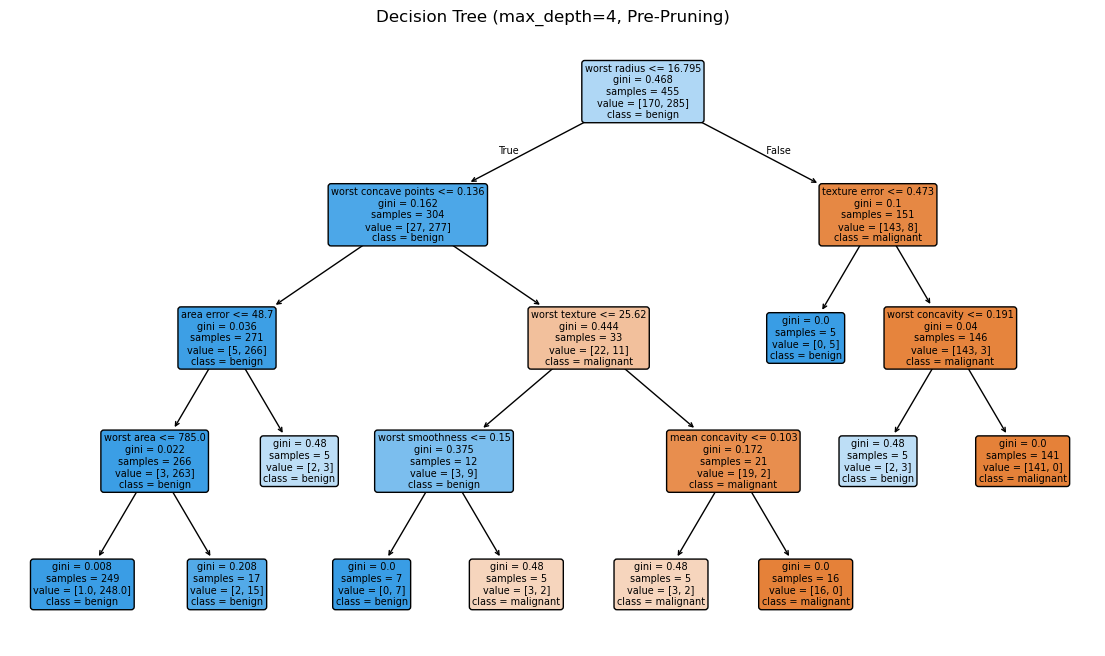

In [7]:
plt.figure(figsize=(14, 8))
plot_tree(
    tree_pruned,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=7,
)
plt.title('Decision Tree (max_depth=4, Pre-Pruning)')
plt.show()